# Q2 — How does the price of the *same* product change over time?

**Question.** For the same product in the same ZIP market, did the listed price move between the first 7 days (21–27 Jul 2026) and the last 7 days (12–18 Aug 2026) of the snapshot?

**Why it matters.** A buyer deciding "buy now or wait" cares about the price of the *same* item, not the average price of whatever happens to be listed that day. Comparing market-wide averages mixes price changes with changes in which products are listed.

**Plan**
1. Load, add flags (`src/cleaning.py`) and apply explicit, logged filters.
2. Cohort structure (continues section 3.2.7 of `01_collection_exploration`): rows per cohort-day, days observed, cohorts usable.
3. Per cohort: median price in the first window vs the last window → log-ratio → median change with two bootstrap CIs (by cohort and by product) + Wilcoxon signed-rank test.
4. Fixed-cohort index vs the naive market median: how much of a "market trend" is only product-mix change?
5. Sensitivity (D6): window 5/7/10, minimum days, keep noise rows, drop unresolved capacity, drop extreme movers.
6. Limitations.

> Only `price_amount` is used (a product is compared with itself), so **unresolved-capacity rows are kept** (team decision, notebook 01 §3.2.5). They only matter for price per GB/TB and are dropped in the sensitivity section. Rows flagged `is_noise` (17 complete computers + 11 NAS appliances) are excluded.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["font.enable_last_resort"] = False
from scipy import stats

sys.path.insert(0, str(ROOT))          # repo root (NOT src/, see io.py docstring)
from src.io import load_raw
from src.cleaning import add_flags, RowLog

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
CATS = ["DDR5", "NVMe"]
LABEL = {"DDR5": "DDR5 (USD per kit / package)", "NVMe": "NVMe (USD per drive)"}
KEY = ["category", "product_name", "geography_id"]   # cohort = same product title in the same ZIP market

## 1. Load and filter (every step logs its row count)

In [2]:
raw = load_raw(columns="keep", validate=True)
df = add_flags(raw)
log = RowLog()
log.note(df, "load raw + add flags", reason="no rows change")
# Sanity check against the full dataset: 17 complete computers (data card) + 11 NAS appliances (found by the team).
ddr5_unflagged = int(((df["category"] == "DDR5") & df["is_unresolved"] & ~df["is_system_noise"]).sum())
display(pd.DataFrame({
    "check": ["system-noise rows", "system-noise titles", "NAS rows", "NAS titles", "unresolved DDR5 rows not flagged"],
    "expected (full data)": [17, 5, 11, 2, 0],
    "actual": [int(df["is_system_noise"].sum()), df.loc[df["is_system_noise"], "product_name"].nunique(),
               int(df["is_nas_noise"].sum()), df.loc[df["is_nas_noise"], "product_name"].nunique(), ddr5_unflagged],
}).assign(ok=lambda t: t["expected (full data)"] == t["actual"]))

# Complete computers and complete NAS appliances are not memory modules / SSDs (RAM sold *for* a NAS is kept).
df = log.step(df, "drop complete-system / NAS rows (DDR5 noise)",
              lambda d: d[~d["is_noise"]],
              reason="not RAM modules; flagged in cleaning.add_flags (is_system_noise | is_nas_noise)")
# Unresolved capacity is KEPT: Q2 compares price_amount of the same product with itself.
log.note(df, "keep unresolved-capacity rows", reason="irrelevant when comparing price_amount of the same product")
log.table()

[OK] All 12 checks match the Kaggle data card.
[load raw + add flags] 127,843 -> 127,843 rows (removed 0)


,check,expected (full data),actual,ok
0,system-noise rows,17,17,True
1,system-noise titles,5,5,True
2,NAS rows,11,11,True
3,NAS titles,2,2,True
4,unresolved DDR5 rows not flagged,0,0,True


[drop complete-system / NAS rows (DDR5 noise)] 127,843 -> 127,815 rows (removed 28)
[keep unresolved-capacity rows] 127,815 -> 127,815 rows (removed 0)


,step,rows_before,rows_after,rows_removed,reason
0,load raw + add flags,127843,127843,0,no rows change
1,drop complete-system / NAS rows (DDR5 noise),127843,127815,28,not RAM modules; flagged in cleaning.add_flags...
2,keep unresolved-capacity rows,127815,127815,0,irrelevant when comparing price_amount of the ...


## 2. Cohort structure (what notebook 01 §3.2.7 found, re-checked here on the filtered rows)

**Cohort** = `category × product_name × geography_id`. The data card warns that an exact title is *not* a unique SKU, so a cohort can have several rows on one day. In notebook 01 this happened in only **0.25 %** of cohort-days (max 2 rows, NVMe only). We check the price gap inside those cases before deciding how to collapse them.

In [3]:
g = df.groupby(KEY + ["observed_date"], observed=True)["price_amount"].agg(["size", "min", "max"])
print("rows per cohort-day:"); display(g["size"].groupby(level="category", observed=True).describe()[["count", "mean", "max"]])
print(f"share of cohort-days with more than one row: {(g['size'] > 1).mean():.2%}")

dup = g[g["size"] > 1]
ratio = (dup["max"] / dup["min"]).rename("max/min price within the same cohort-day")
print(f"\ncohort-days with 2 rows: {len(dup):,}")
print(ratio.describe(percentiles=[.5, .9, .99]).round(4).to_string())

rows per cohort-day:


,count,mean,max
category,,,
DDR5,18622.0,1.000000,1.0
NVMe,108879.0,1.002884,2.0


share of cohort-days with more than one row: 0.25%

cohort-days with 2 rows: 314
count    314.0000
mean       1.0195
std        0.0177
min        1.0032
50%        1.0164
90%        1.0500
99%        1.0625
max        1.0625


**Decision (a).** Same-day duplicates are rare, so collapsing them to one price per cohort-day with the **median** cannot change the result materially. If the max/min ratio above is far from 1, the title hides different items — keep that in the limitations.

In [4]:
def build_daily(d):
    """One price per cohort-day (median of same-day rows)."""
    return d.groupby(KEY + ["observed_date"], observed=True, as_index=False)["price_amount"].median()

daily = log.step(df, "collapse to cohort-day (median price)", build_daily,
                 reason="same-day duplicates are rare (about 0.25% of cohort-days); median is robust")
days_per_cohort = daily.groupby(KEY, observed=True)["observed_date"].nunique().rename("n_days").reset_index()
print("cohorts:", days_per_cohort.groupby("category", observed=True).size().to_dict())
display(days_per_cohort.groupby("category", observed=True)["n_days"].describe().round(1))

[collapse to cohort-day (median price)] 127,815 -> 127,501 rows (removed 314)
cohorts: {'DDR5': 1823, 'NVMe': 9190}


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
DDR5,1823.0,10.2,9.3,1.0,2.0,6.0,15.0,29.0
NVMe,9190.0,11.8,9.5,1.0,3.0,9.0,19.0,29.0


### Coverage of the two windows (the number that decides `min_days`)
From notebook 01: usable cohorts (seen in *both* windows) were **DDR5 555 / 387 / 235** and **NVMe 3,325 / 2,283 / 1,551** for at least 1 / 3 / 5 days per window.

**Decision (b).** Main analysis = **≥ 3 days in each 7-day window** (a median of 3+ days is less sensitive to one missing or odd day; 1 day would let a single listing define a window). DDR5 keeps only 387 cohorts, so **`min_days = 5` leaves DDR5 thin (235) and is used only as a sensitivity check.**

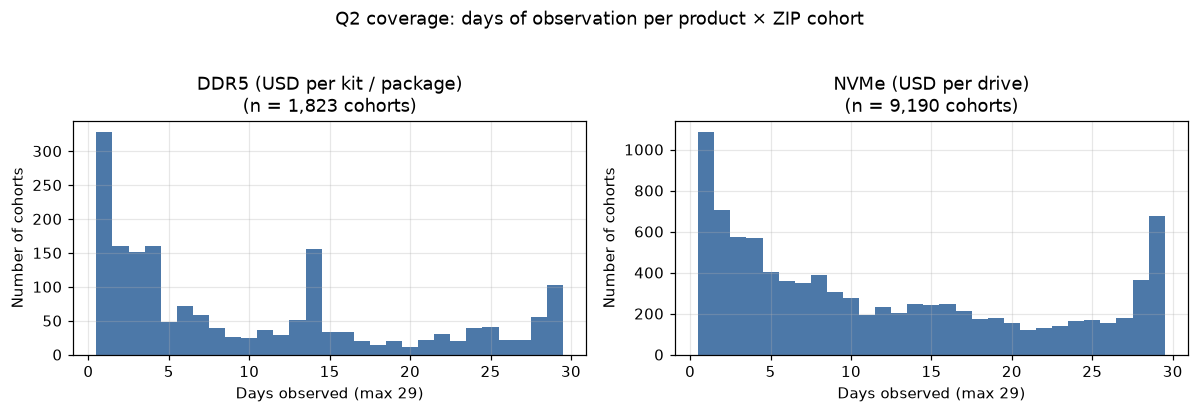

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, c in zip(ax, CATS):
    x = days_per_cohort.loc[days_per_cohort["category"] == c, "n_days"]
    a.hist(x, bins=np.arange(0.5, 30.5, 1), color="#4C78A8")
    a.set(title=f"{LABEL[c]}\n(n = {len(x):,} cohorts)", xlabel="Days observed (max 29)", ylabel="Number of cohorts")
fig.suptitle("Q2 coverage: days of observation per product × ZIP cohort", y=1.03)
plt.tight_layout(); plt.show()

**Reading the coverage plot.** Coverage is uneven: the median DDR5 cohort is seen on only **6 of 29 days** (mean 10.2) and the median NVMe cohort on **9 days** (mean 11.8). Many listings appear for a few days and disappear, which is why only **387 of 1,823** DDR5 cohorts and **2,283 of 9,190** NVMe cohorts have at least 3 days in *both* windows. The results below describe the products that stayed listed from the start to the end of the snapshot.

## 3. Method: first window vs last window (D2, D3, D4)

For each cohort *c*:

- `median_first` / `median_last` = median of its daily prices over the first / last *w* dates (*w* = 7 in the main analysis).
- **Derived variable:** log-ratio `ln(median_last / median_first)`; reported as `% change = exp(log-ratio) − 1`. Log-ratios are symmetric (+10 % and −10 % cancel) and less skewed than raw percentages.
- A cohort is kept only if it has ≥ `min_days` observed days in **both** windows.

Because each cohort is compared with itself, brand, capacity, speed and ZIP are held fixed by construction (confounder control, D4).

**Two bootstrap CIs for the median (D5).**
- *Cohort bootstrap:* resamples cohorts. Simple, but the same title appears in up to 12 ZIPs, so cohorts are **not independent** and this CI is probably too narrow.
- *Product bootstrap (clustered):* resamples `product_name` and keeps all ZIP cohorts of a sampled title together. This is the more honest interval; we report both and rely on the wider one.

In [6]:
def cohort_change(daily, window=7, min_days=3):
    dates = np.sort(daily["observed_date"].unique())
    first, last = dates[:window], dates[-window:]
    d = daily.copy()
    d["period"] = np.select([d["observed_date"].isin(first), d["observed_date"].isin(last)],
                            ["first", "last"], default="")
    d = d[d["period"] != ""]
    g = (d.groupby(KEY + ["period"], observed=True)["price_amount"]
           .agg(["median", "count"]).unstack("period"))
    g.columns = [f"{a}_{b}" for a, b in g.columns]
    g = g.dropna(subset=["median_first", "median_last"])
    g = g[(g["count_first"] >= min_days) & (g["count_last"] >= min_days)].reset_index()
    g["log_ratio"] = np.log(g["median_last"] / g["median_first"])
    g["pct_change"] = np.expm1(g["log_ratio"]) * 100
    return g

def boot_median_ci(x, B=2000, seed=42, chunk=200):
    """Percentile CI of the median, resampling cohorts."""
    rng = np.random.default_rng(seed)
    n = len(x); meds = []
    for _ in range(B // chunk):
        idx = rng.integers(0, n, size=(chunk, n))
        meds.append(np.median(x[idx], axis=1))
    return np.percentile(np.concatenate(meds), [2.5, 97.5])

def boot_median_ci_cluster(x, groups, B=1000, seed=42):
    """Percentile CI of the median, resampling whole products (all ZIP cohorts of a title together)."""
    rng = np.random.default_rng(seed)
    codes, _ = pd.factorize(pd.Series(groups).astype(str))
    order = np.argsort(codes, kind="stable")
    xs, counts = x[order], np.bincount(codes)
    parts = np.split(xs, np.cumsum(counts)[:-1])
    k = len(parts)
    meds = np.empty(B)
    for b in range(B):
        pick = rng.integers(0, k, size=k)
        meds[b] = np.median(np.concatenate([parts[j] for j in pick]))
    return np.percentile(meds, [2.5, 97.5])

SUMMARY_COLS = ["config", "category", "n_cohorts", "n_products", "median_%", "ci_low_%", "ci_high_%",
                "ci_prod_low_%", "ci_prod_high_%", "trimmed_mean_%", "share_up", "share_down", "share_same",
                "wilcoxon_p"]

def summarise(ch, label=""):
    rows = []
    for c, g in ch.groupby("category", observed=True):
        x = g["log_ratio"].to_numpy()
        if len(x) < 10:
            continue
        lo, hi = boot_median_ci(x)
        plo, phi = boot_median_ci_cluster(x, g["product_name"].to_numpy())
        try:
            p = stats.wilcoxon(x).pvalue if np.any(x != 0) else np.nan
        except ValueError:
            p = np.nan
        rows.append({"config": label, "category": c, "n_cohorts": len(x), "n_products": g["product_name"].nunique(),
                     "median_%": np.expm1(np.median(x)) * 100,
                     "ci_low_%": np.expm1(lo) * 100, "ci_high_%": np.expm1(hi) * 100,
                     "ci_prod_low_%": np.expm1(plo) * 100, "ci_prod_high_%": np.expm1(phi) * 100,
                     "trimmed_mean_%": np.expm1(stats.trim_mean(x, 0.05)) * 100,
                     "share_up": (x > 0).mean(), "share_down": (x < 0).mean(), "share_same": (x == 0).mean(),
                     "wilcoxon_p": p})
    return pd.DataFrame(rows, columns=SUMMARY_COLS)

In [7]:
ch = cohort_change(daily, window=7, min_days=3)
log.records.append({"step": "cohorts with >=3 days in BOTH 7-day windows", "rows_before": len(days_per_cohort),
                    "rows_after": len(ch), "rows_removed": len(days_per_cohort) - len(ch),
                    "reason": "need repeated observations in the first and the last window"})
print(f"cohorts: {len(days_per_cohort):,} -> {len(ch):,}")
print(ch.groupby("category", observed=True).agg(cohorts=("log_ratio", "size"), products=("product_name", "nunique")))
main = summarise(ch, "main: w=7, min_days=3")
main.round(3)

cohorts: 11,013 -> 2,670
          cohorts  products
category                   
DDR5          387        49
NVMe         2283       290


,config,category,n_cohorts,n_products,median_%,ci_low_%,ci_high_%,ci_prod_low_%,ci_prod_high_%,trimmed_mean_%,share_up,share_down,share_same,wilcoxon_p
0,"main: w=7, min_days=3",DDR5,387,49,4.396,3.448,5.634,2.128,8.696,5.485,0.682,0.127,0.191,0.000
1,"main: w=7, min_days=3",NVMe,2283,290,0.000,0.000,0.000,0.000,0.000,0.317,0.284,0.263,0.452,0.034


### Main result

| | DDR5 (USD per kit) | NVMe (USD per drive) |
|---|---|---|
| Cohorts (distinct products) | 387 (49) | 2,283 (290) |
| **Median change, same product, last 7 d vs first 7 d** | **+4.40 %** | **0.00 %** |
| 95 % CI, resampling cohorts | [+3.45, +5.63] % | [0, 0] % |
| 95 % CI, resampling products (more honest) | [+2.13, +8.70] % | [0, 0] % |
| 5 % trimmed mean | +5.49 % | +0.32 % |
| Cohorts up / down / unchanged | 68.2 % / 12.7 % / 19.1 % | 28.4 % / 26.3 % / 45.2 % |
| Wilcoxon signed-rank p | < 0.001 | 0.034 |

**DDR5.** The median same-product price rose by **+4.4 %** (95 % CI by cohort [+3.4, +5.6] %; by product [+2.1, +8.7] %; n = 387 cohorts from 49 products). **68 %** of cohorts rose and only **13 %** fell (Wilcoxon p < 0.001). Even the wider product-level interval excludes 0, so DDR5 prices drifted **up** over these 29 days. The size is uncertain (roughly +2 % to +9 %) because the 387 cohorts come from only 49 distinct titles.

**NVMe.** The median change is **exactly 0 %** and both CIs are [0, 0]. This does **not** mean "zero uncertainty": **45 % of cohorts are unchanged**, so the median sits on that spike and the bootstrap median cannot leave it. What the numbers do say:
- A *typical* NVMe drive had the same price at the start and the end.
- The market is **not** frozen: **55 %** of cohorts changed, and ups (28 %) and downs (26 %) are almost balanced.
- The trimmed mean is +0.32 %, i.e. close to 0 as well.
- The Wilcoxon p = 0.034 should **not** be over-read: it ignores the unchanged cohorts (scipy drops zero differences), assumes independent cohorts, and in the sensitivity table it ranges from < 0.001 to 0.52 depending on the choice made (section 6).

So for NVMe the correct statement is **"no detectable drift in the typical product over these 29 days"**, not "NVMe prices are stable".

### Sanity check: the biggest movers (real changes, or different items behind one title?)

In [8]:
cols = KEY + ["median_first", "median_last", "count_first", "count_last", "pct_change"]
print("Largest increases"); display(ch.nlargest(8, "pct_change")[cols].round(2))
print("Largest decreases"); display(ch.nsmallest(8, "pct_change")[cols].round(2))

Largest increases


,category,product_name,geography_id,median_first,median_last,count_first,count_last,pct_change
1891,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,11385,32.99,58.9,4.0,6.0,78.54
1892,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,19145,32.99,58.9,4.0,7.0,78.54
1893,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,32210,32.99,58.9,3.0,7.0,78.54
1894,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,39206,32.99,58.9,4.0,7.0,78.54
1895,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,60618,32.99,58.9,3.0,6.0,78.54
1896,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,62201,32.99,58.9,3.0,6.0,78.54
1897,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,63105,32.99,58.9,3.0,7.0,78.54
1898,NVMe,SK hynix 128GB PCIe NVMe M.2 SSD Internal Soli...,77004,32.99,58.9,7.0,7.0,78.54


Largest decreases


,category,product_name,geography_id,median_first,median_last,count_first,count_last,pct_change
2074,NVMe,Samsung SSD PM9A1 M.2 NVMe 512GB,77004,142.0,95.0,7.0,7.0,-33.1
2075,NVMe,Samsung SSD PM9A1 M.2 NVMe 512GB,78228,142.0,95.0,6.0,7.0,-33.1
2076,NVMe,Samsung SSD PM9A1 M.2 NVMe 512GB,90019,142.0,95.0,7.0,7.0,-33.1
2077,NVMe,Samsung SSD PM9A1 M.2 NVMe 512GB,95123,142.0,95.0,6.0,7.0,-33.1
2078,NVMe,Samsung SSD PM9A1 M.2 NVMe 512GB,98118,142.0,95.0,7.0,7.0,-33.1
2008,NVMe,Samsung PM9A1 MZ-VL21T100 1TB PCIe 4.0 NVMe 22...,11385,297.0,199.0,7.0,7.0,-33.0
2009,NVMe,Samsung PM9A1 MZ-VL21T100 1TB PCIe 4.0 NVMe 22...,19145,297.0,199.0,7.0,7.0,-33.0
2010,NVMe,Samsung PM9A1 MZ-VL21T100 1TB PCIe 4.0 NVMe 22...,32210,297.0,199.0,7.0,7.0,-33.0


**What the biggest movers tell us.**
- The same title has an **identical** first/last price in every ZIP (for example SK hynix 128GB: 32.99 → 58.90 in all eight ZIPs shown; Samsung PM9A1 512GB: 142 → 95 in five ZIPs shown). Prices therefore change **per product across the whole market**, not locally. This is why cohorts of the same title are not independent and why the **product-level bootstrap** is the CI to trust.
- Whether these extremes are real repricing (+78.5 %, −33 %) or *different items sold under one title* (the data card warns that a title is not a unique SKU) cannot be decided from this dataset. The robustness section drops all |change| > 50 % cohorts to show that this question does not drive the main result.

## 4. Plot 1 — distribution of cohort-level changes

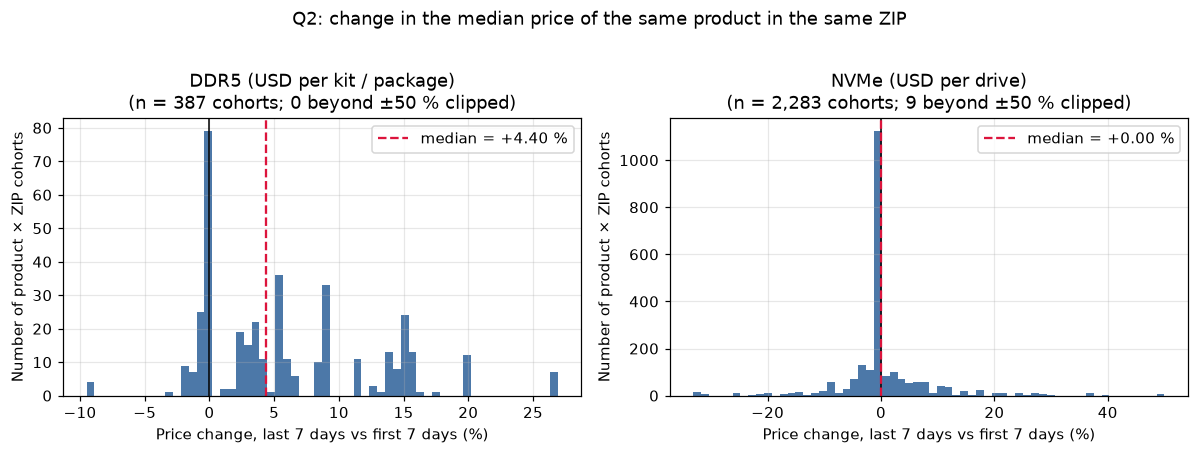

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
CLIP = 50
for a, c in zip(ax, CATS):
    x = ch.loc[ch["category"] == c, "pct_change"]
    a.hist(x.clip(-CLIP, CLIP), bins=60, color="#4C78A8")
    a.axvline(0, color="k", lw=1)
    a.axvline(x.median(), color="crimson", ls="--", label=f"median = {x.median():+.2f} %")
    a.set(title=f"{LABEL[c]}\n(n = {len(x):,} cohorts; {(x.abs() > CLIP).sum()} beyond ±{CLIP} % clipped)",
          xlabel="Price change, last 7 days vs first 7 days (%)", ylabel="Number of product × ZIP cohorts")
    a.legend()
fig.suptitle("Q2: change in the median price of the same product in the same ZIP", y=1.02)
plt.tight_layout(); plt.show()

**Reading Plot 1.**
- **DDR5:** the distribution is clearly **shifted to the right** of 0. A spike of ≈ 80 cohorts is unchanged; almost everything else sits between about +2 % and +27 %, in clusters (around +5 %, +9 %, +15 %, +20 %), which look like a few products being repriced in discrete steps. Only a handful of cohorts fall (around −10 %). The median (+4.4 %) is a typical case; the 5 % trimmed mean (+5.5 %) is higher because of the right tail.
- **NVMe:** a very tall spike at 0 (≈ 1,100 cohorts) with **roughly symmetric, heavy tails** to both sides (about ±30 %; 9 cohorts beyond ±50 % are clipped). Large moves exist but cancel out, so the median and the mean are close to 0.

## 5. Plot 2 — fixed-cohort index vs naive market median (D2, D4)

- **Naive market median:** median `price_amount` of *all* kept rows each day. It also moves when the **mix** of listed products changes.
- **Fixed-cohort index:** only the cohorts kept in section 3; each cohort's daily price is divided by its own first-window median and the median across cohorts is taken each day. The product mix is held constant.

If the two lines disagree, part of the naive "market trend" is a catalogue effect — which is exactly why Q2 asks about the same product.

daily rows 127,501 -> 66,581 after restricting to the kept cohorts (inner merge)


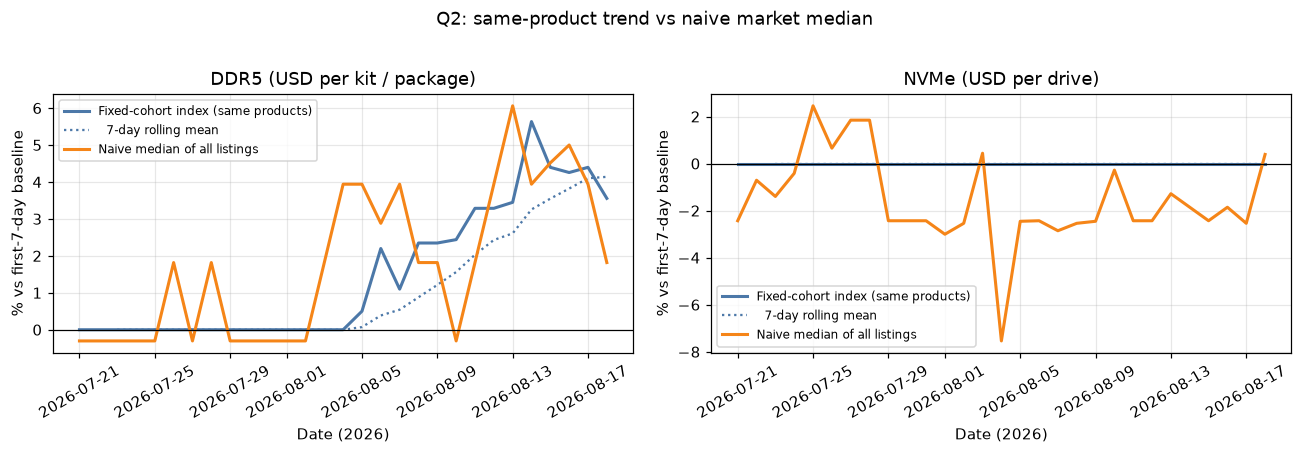

In [10]:
def fixed_cohort_index(daily, ch):
    m = daily.merge(ch[KEY + ["median_first"]], on=KEY, how="inner", validate="many_to_one")
    m["log_rel"] = np.log(m["price_amount"] / m["median_first"])
    idx = m.groupby(["category", "observed_date"], observed=True)["log_rel"].median()
    return np.expm1(idx) * 100, len(m)

idx, n_merge = fixed_cohort_index(daily, ch)
print(f"daily rows {len(daily):,} -> {n_merge:,} after restricting to the kept cohorts (inner merge)")

naive = df.groupby(["category", "observed_date"], observed=True)["price_amount"].median()
first7 = np.sort(df["observed_date"].unique())[:7]
base = (naive[naive.index.get_level_values("observed_date").isin(first7)]
        .groupby(level="category", observed=True).mean())
naive_pct = (naive / base.reindex(naive.index.get_level_values("category")).to_numpy() - 1) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, c in zip(ax, CATS):
    i = idx.xs(c, level="category"); n = naive_pct.xs(c, level="category")
    a.plot(i.index, i.values, label="Fixed-cohort index (same products)", color="#4C78A8", lw=2)
    a.plot(i.index, i.rolling(7, min_periods=3).mean(), color="#4C78A8", ls=":", label="  7-day rolling mean")
    a.plot(n.index, n.values, label="Naive median of all listings", color="#F58518", lw=2)
    a.axhline(0, color="k", lw=.8)
    a.set(title=LABEL[c], xlabel="Date (2026)", ylabel="% vs first-7-day baseline")
    a.legend(fontsize=8); a.tick_params(axis="x", rotation=30)
fig.suptitle("Q2: same-product trend vs naive market median", y=1.02)
plt.tight_layout(); plt.show()

**Reading Plot 2 (D2, D4).**
- **DDR5:** the fixed-cohort index stays at ≈ 0 % until about 4 Aug, then climbs to a peak of ≈ +5.6 % (about 13–14 Aug) and ends at ≈ +3.6 % on 18 Aug (7-day rolling mean ≈ +4 %). So the rise is concentrated in the **second half** of the snapshot and is not a smooth trend. The naive median of all listings is much more jagged: it jumps between ≈ −0.3 % and ≈ +6 % within a few days and ends at only ≈ +1.8 %, because it also reacts to which products are listed on a given day.
- **NVMe:** the fixed-cohort index is a flat line at 0 (the median across cohorts is pinned by the 45 % unchanged cohorts), whereas the naive median wanders between ≈ −7.5 % and ≈ +2.5 % and sits around −2 to −3 % for most of August. The apparent "NVMe got about 2–3 % cheaper" in the naive series is therefore a **catalogue (mix) effect**, not a typical price cut of the same drive.
- Caveat: the two lines use different baselines (naive: mean of the first 7 daily medians; fixed-cohort: each cohort's own first-window median), so compare their *shape* rather than the exact level.

### Breakdown by ZIP (descriptive; only 12 ZIPs)

In [11]:
(ch.groupby(["category", "geography_id"], observed=True)
   .agg(n_cohorts=("log_ratio", "size"), median_pct=("pct_change", "median")).round(2)
   .unstack("category"))

n_cohorts      median_pct     
category          DDR5 NVMe       DDR5 NVMe
geography_id                               
11385               30  185       3.62  0.0
19145               30  202       5.22  0.0
32210               29  193       3.45  0.0
39206               31  200       5.63  0.0
60618               35  188       5.63  0.0
62201               34  187       5.01  0.0
63105               34  182       3.50  0.0
77004               36  187       5.01  0.0
78228               35  193       4.40  0.0
90019               30  190       5.63  0.0
95123               34  191       3.98  0.0
98118               29  185       5.63  0.0

**Reading the ZIP breakdown (descriptive, 12 ZIPs).** The DDR5 median change is positive in **every** ZIP and varies only between +3.5 % and +5.6 %, with 29–36 cohorts per ZIP; the NVMe median is 0.0 in every ZIP (182–202 cohorts per ZIP). No ZIP drives the result, which fits the earlier finding that a title is priced the same across ZIPs. The small differences between ZIPs reflect which DDR5 titles happen to be observed in both windows there, not a regional effect.

## 6. Robustness (D6): does the conclusion survive other reasonable choices?

Varied: window length (5 / 7 / 10 days), minimum days per window (1 / 3 / 5), keeping the noise rows (system + NAS), dropping unresolved-capacity rows, and dropping extreme movers (|change| > 50 %). Each line shows the median change with the **product-level** CI.

In [12]:
def run(label, daily_df, window=7, min_days=3, max_abs=None):
    c = cohort_change(daily_df, window, min_days)
    if max_abs is not None:
        c = c[c["pct_change"].abs() <= max_abs]
    return summarise(c, label)

# alternative inputs, built from the logged pipeline (raw data is never edited)
daily_noise    = build_daily(add_flags(raw))                      # noise rows (system + NAS) kept
daily_resolved = build_daily(df[~df["is_unresolved"]])            # unresolved capacity dropped

sens = pd.concat([
    run("main: w=7, min_days=3", daily),
    run("window 5", daily, window=5),
    run("window 10", daily, window=10),
    run("min_days 1", daily, min_days=1),
    run("min_days 5", daily, min_days=5),
    run("keep noise rows (system + NAS)", daily_noise),
    run("drop unresolved capacity", daily_resolved),
    run("drop |change| > 50%", daily, max_abs=50),
], ignore_index=True)
sens.round(3)

,config,category,n_cohorts,n_products,median_%,ci_low_%,ci_high_%,ci_prod_low_%,ci_prod_high_%,trimmed_mean_%,share_up,share_down,share_same,wilcoxon_p
0,"main: w=7, min_days=3",DDR5,387,49,4.396,3.448,5.634,2.128,8.696,5.485,0.682,0.127,0.191,0.000
1,"main: w=7, min_days=3",NVMe,2283,290,0.000,0.000,0.000,0.000,0.000,0.317,0.284,0.263,0.452,0.034
2,window 5,DDR5,258,35,3.448,2.128,6.383,0.000,9.091,5.809,0.632,0.116,0.252,0.000
3,window 5,NVMe,1771,234,0.000,0.000,0.000,0.000,0.000,0.411,0.292,0.266,0.442,0.048
4,window 10,DDR5,471,57,3.556,3.448,4.460,0.901,5.689,4.792,0.660,0.100,0.240,0.000
5,window 10,NVMe,2799,342,0.000,0.000,0.000,0.000,0.000,0.534,0.272,0.239,0.489,0.000
6,min_days 1,DDR5,555,67,4.396,3.448,5.634,2.128,6.383,5.479,0.659,0.119,0.222,0.000
7,min_days 1,NVMe,3325,400,0.000,0.000,0.000,0.000,0.000,0.058,0.279,0.269,0.452,0.519
8,min_days 5,DDR5,235,31,3.448,2.439,8.696,0.000,11.364,6.191,0.660,0.140,0.200,0.000
9,min_days 5,NVMe,1551,212,0.000,0.000,0.000,0.000,0.000,0.345,0.301,0.285,0.414,0.087


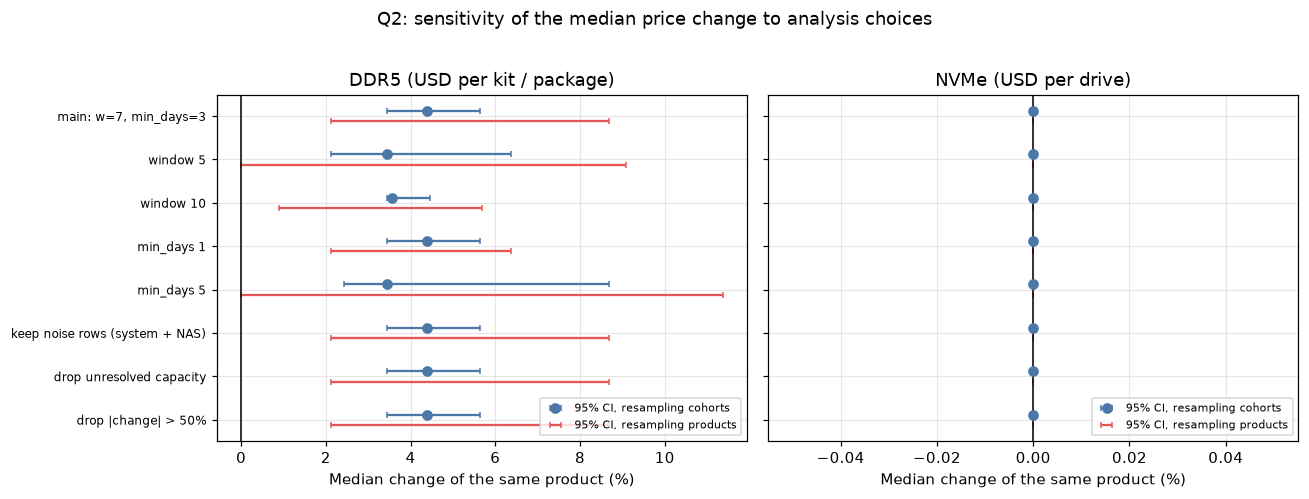

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for a, c in zip(ax, CATS):
    t = sens[sens["category"] == c].reset_index(drop=True)
    if t.empty:
        a.set_title(f"{LABEL[c]} (not enough cohorts)"); continue
    y = np.arange(len(t))[::-1]
    a.errorbar(t["median_%"], y + .12, xerr=[t["median_%"] - t["ci_low_%"], t["ci_high_%"] - t["median_%"]],
               fmt="o", color="#4C78A8", capsize=2, label="95% CI, resampling cohorts")
    a.errorbar(t["median_%"], y - .12, xerr=[t["median_%"] - t["ci_prod_low_%"], t["ci_prod_high_%"] - t["median_%"]],
               fmt="none", ecolor="#E45756", capsize=2, label="95% CI, resampling products")
    a.axvline(0, color="k", lw=1)
    a.set_yticks(y); a.set_yticklabels(t["config"], fontsize=8)
    a.set(title=LABEL[c], xlabel="Median change of the same product (%)")
    a.legend(fontsize=7, loc="lower right")
fig.suptitle("Q2: sensitivity of the median price change to analysis choices", y=1.02)
plt.tight_layout(); plt.show()

**Reading the robustness plot (D6).**
- **DDR5:** across all eight configurations the median change stays between **+3.4 % and +4.4 %** and the sign never flips; 63–68 % of cohorts rise and 10–14 % fall. The cohort-level CI never includes 0. The **product-level CI touches 0** only in the two thinnest settings (*window 5*: 258 cohorts / 35 products; *min_days 5*: 235 / 31), where there are simply too few distinct titles. With the 10-day window the CI is [+0.9, +5.7] %.
- **Noise rows and unresolved capacity:** identical DDR5 results (387 cohorts, 49 products), so the 28 noise rows never enter the usable DDR5 cohorts. For NVMe, dropping unresolved-capacity rows removes 53 cohorts (9 products) and changes nothing.
- **Extreme movers:** dropping |change| > 50 % removes only 9 NVMe cohorts (the trimmed mean moves from +0.32 % to +0.26 %) and nothing for DDR5.
- **NVMe:** the median is 0 and the CI is [0, 0] in **every** configuration, so "no typical change" is robust. The Wilcoxon p-value is not (from < 0.001 to 0.52), which is one more reason not to claim a significant NVMe effect.

## 7. Answer, practical meaning, limitations

- **Answer (with numbers):**
  - **DDR5: yes, prices rose.** The same DDR5 product in the same ZIP was **+4.4 %** more expensive in the last 7 days than in the first 7 days (95 % CI by product [+2.1, +8.7] %; 387 cohorts, 49 products); 68 % of cohorts rose, 13 % fell.
  - **NVMe: no detectable change for the typical product.** Median **0 %**, 45 % of cohorts unchanged, 28 % up vs 26 % down, trimmed mean +0.3 %. Individual drives can still move a lot (tails around ±30 %).
- **Does the fixed-cohort trend differ from the naive trend?** Yes, in both categories. For DDR5 the naive median is jagged and ends lower (≈ +1.8 % vs ≈ +3.6 % for the fixed cohort on 18 Aug). For NVMe the naive median suggests a 2–3 % fall that the same-product comparison does not show: it is a **product-mix effect**. This is the main reason the question is asked about the *same* product.
- **Robust?** The DDR5 sign and size (+3.4 % to +4.4 %) survive every change of window, minimum days, noise rows, unresolved capacity and extreme movers. The only weakness is that the product-level CI reaches 0 when the sample shrinks to about 31–35 titles (window 5, min_days 5). The NVMe median of 0 holds in every row of the sensitivity table; the NVMe Wilcoxon p-value does not.
- **Practical meaning.** For a buyer: during 21 Jul – 18 Aug 2026 a typical DDR5 kit became about 4 % more expensive (illustratively, about +$4 on a $100 kit), mostly in the second half of the period, while a typical NVMe drive did not change. For NVMe, check the specific product, because some move ±30 %. The data show what happened, not what will happen: they cannot tell a buyer whether to wait.
- **Surprises.** (1) The median NVMe change is exactly 0 even though 55 % of cohorts moved: up and down cancel. (2) Price changes are identical across ZIPs for the same title, so the market effectively sets one price per title. (3) The naive market median gives a misleading picture of NVMe.
- **Criteria covered:** D2 (first vs last window, rolling index), D3 (log-ratio), D4 (each cohort is its own control), D5 (two bootstrap CIs, Wilcoxon), D6 (eight alternative choices).
- **Limitations (keep these unless the data show otherwise):**
  - Only 29 days → short-term movement; no seasonality or long-term trend can be inferred. The data also do not explain *why* DDR5 rose.
  - Exact-title cohorts are not unique SKUs (data card); same-day duplicates (≈ 0.25 % of cohort-days, max/min price ratio ≤ 1.06) were collapsed with the median. The biggest movers could be different items under one title.
  - The same title appears in several ZIPs at the same price, so cohorts are not independent; only the product-level bootstrap accounts for this (the cohort-level CI and the Wilcoxon p-value do not). The DDR5 result rests on only 49 distinct titles.
  - Cohorts must be observed in **both** windows; listings that appear or disappear are excluded (possible survivorship bias, direction unknown). DDR5 keeps 387 of 1,823 cohorts (21 %), NVMe 2,283 of 9,190 (25 %).
  - A median of 0 hides the 55 % of NVMe cohorts that moved; the median alone is not a measure of volatility (that is Q4).
  - Listed prices, not transactions.